# Wildfire Evacuation Alert-Failure — Data Analysis

Loads the CSVs produced by `collect_data.py` (GDELT news coverage + Reddit
submissions/comments/subreddit-local for the Lahaina and Camp Fire case
studies) and runs burst detection on each, to compare when informal online
awareness spiked against the official warning timeline from each AG/
investigation report.

**In Colab:** run the cells top to bottom. The second code cell will prompt
you to upload CSVs — select all of them at once (multi-select works in the
picker): `lahaina_*.csv`, `camp_fire_*.csv`, including any
`*_reddit_local.csv` / `*_reddit_local_comments.csv` files you have.

**Running locally instead:** no upload needed — `DATA_DIR` defaults to
`../data`, the project's `data/` folder (this notebook lives in `src/`).

In [21]:
!pip install -q pandas matplotlib

In [22]:
import os

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

DATA_DIR = "../data"  # project's data/ folder (notebook lives in src/)

if IN_COLAB:
    from google.colab import files
    print("Select all your CSVs (lahaina_*.csv, camp_fire_*.csv, *_reddit_local*.csv) "
          "-- multi-select is fine.")
    uploaded = files.upload()
    DATA_DIR = "."

print(f"Looking for CSVs in: {os.path.abspath(DATA_DIR)}")

Looking for CSVs in: /Users/aneeshghosal/Documents/ML/data


## Discover which CSVs are present

In [23]:
import glob

CASES = ["lahaina", "camp_fire"]
SOURCE_SUFFIXES = {
    "gdelt": "_gdelt.csv",
    "reddit_submissions": "_reddit_submissions.csv",
    "reddit_comments": "_reddit_comments.csv",
}

def find_case_files(case, data_dir=DATA_DIR):
    found = {}
    for label, suffix in SOURCE_SUFFIXES.items():
        path = os.path.join(data_dir, f"{case}{suffix}")
        if os.path.exists(path):
            found[label] = path
    # Subreddit-local files are named <case>_<subreddit>_reddit_local.csv
    for path in sorted(glob.glob(os.path.join(data_dir, f"{case}_*_reddit_local.csv"))):
        sub = os.path.basename(path).replace(f"{case}_", "").replace("_reddit_local.csv", "")
        found[f"local_{sub}"] = path
    # ...and their comments: <case>_<subreddit>_reddit_local_comments.csv
    for path in sorted(glob.glob(os.path.join(data_dir, f"{case}_*_reddit_local_comments.csv"))):
        sub = os.path.basename(path).replace(f"{case}_", "").replace("_reddit_local_comments.csv", "")
        found[f"local_comments_{sub}"] = path
    return found

case_files = {case: find_case_files(case) for case in CASES}
for case, found in case_files.items():
    print(f"{case}: found {list(found.keys())}")
    missing_core = set(SOURCE_SUFFIXES) - set(found)
    if missing_core:
        print(f"  (missing: {sorted(missing_core)} -- rerun collect_data.py for these if you need them)")

lahaina: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_Hawaii', 'local_Maui', 'local_comments_Hawaii', 'local_comments_Maui']
camp_fire: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_California', 'local_Chico', 'local_comments_California', 'local_comments_Chico']


## Load each CSV and parse timestamps

In [24]:
import pandas as pd

def load_with_timestamp(path, timestamp_col):
    try:
        df = pd.read_csv(path, low_memory=False)
    except pd.errors.EmptyDataError:  # e.g. a subreddit with no posts in the window
        df = pd.DataFrame()
        df["_timestamp"] = pd.Series(dtype="datetime64[ns]")
        return df
    if timestamp_col not in df.columns:
        print(f"  ! '{timestamp_col}' not in {os.path.basename(path)}; columns: {list(df.columns)}")
        df["_timestamp"] = pd.NaT
        return df
    col = df[timestamp_col]
    if col.dtype == object and col.astype(str).str.contains("T").any():
        # GDELT-style: 20230809T120000Z
        ts = pd.to_datetime(col, format="%Y%m%dT%H%M%SZ", errors="coerce", utc=True)
    else:
        # Reddit-style: unix epoch seconds
        ts = pd.to_datetime(col, unit="s", errors="coerce", utc=True)
    # naive UTC for every source, so GDELT and Reddit times (and the official
    # timeline) can be compared and subtracted
    df["_timestamp"] = ts.dt.tz_convert(None)
    return df

data = {}  # data[case][source_label] = DataFrame with a "_timestamp" column
for case, found in case_files.items():
    data[case] = {}
    for label, path in found.items():
        ts_col = "seendate" if label == "gdelt" else "created_utc"
        df = load_with_timestamp(path, ts_col)
        data[case][label] = df
        n_valid = df["_timestamp"].notna().sum()
        if n_valid:
            print(f"{case} / {label}: {len(df)} rows, "
                  f"{df['_timestamp'].min()} to {df['_timestamp'].max()}")
        else:
            print(f"{case} / {label}: {len(df)} rows, no valid timestamps")

lahaina / gdelt: 3875 rows, 2023-08-08 17:00:00 to 2023-08-12 00:45:00
lahaina / reddit_submissions: 212 rows, 2023-08-09 08:02:56 to 2023-08-11 03:58:34
lahaina / reddit_comments: 445 rows, 2023-08-09 02:59:56 to 2023-08-11 03:39:00
lahaina / local_Hawaii: 187 rows, 2023-08-08 04:02:45 to 2023-08-11 03:58:34
lahaina / local_Maui: 333 rows, 2023-08-08 07:57:05 to 2023-08-11 03:50:32
lahaina / local_comments_Hawaii: 4163 rows, 2023-08-08 04:01:11 to 2023-08-11 03:59:37
lahaina / local_comments_Maui: 3900 rows, 2023-08-08 11:58:17 to 2023-08-10 20:17:15
camp_fire / gdelt: 1641 rows, 2018-11-08 18:00:00 to 2018-11-13 00:45:00
camp_fire / reddit_submissions: 72 rows, 2018-11-08 21:18:08 to 2018-11-12 00:53:18
camp_fire / reddit_comments: 55 rows, 2018-11-08 23:03:31 to 2018-11-12 04:14:50
camp_fire / local_California: 230 rows, 2018-11-08 07:46:50 to 2018-11-12 03:57:48
camp_fire / local_Chico: 0 rows, no valid timestamps
camp_fire / local_comments_California: 2903 rows, 2018-11-08 05:00:1

## Keep only fire-related local posts

The local-subreddit files (`local_*`) are *everything* posted in r/Hawaii,
r/Maui, r/California, etc., including unrelated chatter whose normal daily
rhythm can look like a burst. This adds a filtered copy of each local source,
labelled `<source>_fire`, that keeps only posts/comments matching the terms
below. The unfiltered sources stay too, so burst detection, the plot and the
lag table show both.

Two levels of terms per case:
- **`place`**: names this specific fire or place: the cleanest "awareness of
  *this* fire" signal, but misses comments like "the fire is getting closer".
- **`general`**: any fire/evacuation talk. Catches more, but on Nov 8 2018 the
  Woolsey and Hill fires also started in Southern California, so for the
  Camp Fire `general` mixes those in.

`FILTER_MODE` picks which one each case uses (`"place"`, `"general"`, or
`"either"` for both combined). The counts printed below show what each would keep.

In [25]:
import re

FIRE_TERMS = {
    "lahaina": {
        "place":   r"lahaina|lahainaluna|front st(?:reet)?|wahikuli|kelawea|west maui|honoapi\w*|kula|upcountry",
        "general": r"fires?|wildfires?|brush ?fires?|smoke|evacuat\w*|burn(?:ed|ing|t|s)?|flames?|embers?|"
                   r"shelters?|sirens?|red cross|power (?:is )?out|outages?",
    },
    "camp_fire": {
        "place":   r"camp ?fire|paradise|butte|chico|magalia|concow|pulga|oroville|feather river|skyway",
        "general": r"fires?|wildfires?|smoke|evacuat\w*|burn(?:ed|ing|t|s)?|flames?|embers?|"
                   r"shelters?|air quality|aqi|red cross",
    },
}
# Lahaina: "general" -- every fire on Maui that day was part of the same disaster.
# Camp Fire: "place" -- "general" would pull in the Woolsey/Hill fires in SoCal.
FILTER_MODE = {"lahaina": "general", "camp_fire": "place"}
KEEP_UNFILTERED_LOCAL = True  # set False to drop the raw local_* sources and declutter the plot


def post_text(df):
    """Title + body for posts, body for comments."""
    parts = [df[c].fillna("").astype(str) for c in ("title", "selftext", "body") if c in df.columns]
    if not parts:
        return pd.Series("", index=df.index)
    text = parts[0]
    for part in parts[1:]:
        text = text + " " + part
    return text


def matches(text, case, mode):
    terms = FIRE_TERMS[case]
    pattern = {"place": terms["place"], "general": terms["general"],
               "either": terms["place"] + "|" + terms["general"]}[mode]
    return text.str.contains(rf"\b(?:{pattern})\b", case=False, regex=True)


for case in CASES:
    print(f"\n=== {case} (using '{FILTER_MODE[case]}') ===")
    print(f"  {'source':30s} {'rows':>6} {'place':>7} {'general':>8} {'either':>7}")
    for label in [l for l in list(data[case]) if l.startswith("local") and not l.endswith("_fire")]:
        df = data[case][label]
        if df.empty:
            continue
        text = post_text(df)
        counts = {m: int(matches(text, case, m).sum()) for m in ("place", "general", "either")}
        print(f"  {label:30s} {len(df):6d} {counts['place']:7d} {counts['general']:8d} {counts['either']:7d}")
        keep = matches(text, case, FILTER_MODE[case])
        data[case][f"{label}_fire"] = df[keep].copy()
        if not KEEP_UNFILTERED_LOCAL:
            del data[case][label]

    # a few random matches from the busiest filtered source, to eyeball the filter
    fire_labels = [l for l in data[case] if l.endswith("_fire")]
    if fire_labels:
        biggest = max(fire_labels, key=lambda l: len(data[case][l]))
        sample = data[case][biggest]
        if len(sample):
            print(f"\n  sample from {biggest}:")
            for t in post_text(sample.sample(min(5, len(sample)), random_state=0)):
                print("   -", " ".join(t.split())[:110])


=== lahaina (using 'general') ===
  source                           rows   place  general  either
  local_Hawaii                      187      42       72      90
  local_Maui                        333     107      135     187
  local_comments_Hawaii            4163     234      688     826
  local_comments_Maui              3900     449      793    1064

  sample from local_comments_Maui_fire:
   - Looks like the library might still be standing, albeit with severe fire damage to the roof, if the interior is
   - im also talking about Kula too dickhead. i heard conflicting reports about kula ace. there isn't exaclty clear
   - Thank you for the clarification. I wonder if the water spots mean maybe some boats caught fire? The few pictur
   - Unfortunately, all of us who have survived wildfires have lots of good advice learned the hard way. This is an
   - This is the stupidest Facebook conspiracy shit worthy of qanon. Do you people just turn off your brains when y

=== camp_fire (usi

## Burst detection

Same approach as `analyze_burst.py`: bin each source into hourly buckets and
z-score each hour against the **24 hours before it** (the hour itself is not
part of its own baseline). The spread is floored at Poisson noise
(`sqrt(mean)`, min 1) so a near-silent baseline can't make a handful of posts
look like a spike, and nothing is flagged until 6 hours of history exist.
A burst is z ≥ 3.

Note the local-subreddit sources are *everything* posted there, not just
fire-related posts, so their bursts can partly reflect the normal daily
rhythm (e.g. a morning rise in activity). Check them against the content
cell at the bottom before reading too much into them.

In [26]:
import numpy as np

def compute_burst(timestamps, freq="h", baseline_window=24, z_threshold=3.0, min_baseline=6):
    """Count events per `freq` bucket and z-score each bucket against the
    `baseline_window` buckets *before* it (the bucket itself is excluded --
    including it, as an earlier version did, caps z at (n-1)/sqrt(n), about
    2.04 for a 6-bucket window, so real spikes never cleared the threshold).
    The std is floored at sqrt(mean) (Poisson noise, min 1) so a near-empty
    baseline can't turn a handful of posts into a huge z. No burst can be
    flagged until `min_baseline` buckets of history exist."""
    ts = timestamps.dropna()
    if ts.empty:
        return pd.DataFrame(columns=["count", "baseline_mean", "z_score", "burst"])
    counts = ts.dt.floor(freq).value_counts().sort_index()
    counts = counts.asfreq(freq, fill_value=0)
    prior = counts.shift(1)
    mean = prior.rolling(baseline_window, min_periods=min_baseline).mean()
    std = prior.rolling(baseline_window, min_periods=min_baseline).std()
    noise_floor = np.maximum(np.sqrt(mean), 1)
    z = (counts - mean) / np.maximum(std, noise_floor)
    result = pd.DataFrame({"count": counts, "baseline_mean": mean, "z_score": z})
    result["burst"] = result["z_score"] >= z_threshold
    return result

burst_results = {}
for case in CASES:
    burst_results[case] = {}
    for label, df in data[case].items():
        result = compute_burst(df["_timestamp"])
        burst_results[case][label] = result
        if not result.empty and result["burst"].any():
            first_burst = result.index[result["burst"]].min()
            print(f"{case} / {label}: first burst at {first_burst}")
        else:
            max_z = result["z_score"].max() if not result.empty else float("nan")
            print(f"{case} / {label}: no burst (max z {max_z:.2f}, {len(df)} rows)")

lahaina / gdelt: first burst at 2023-08-09 11:00:00
lahaina / reddit_submissions: first burst at 2023-08-09 21:00:00
lahaina / reddit_comments: first burst at 2023-08-09 08:00:00
lahaina / local_Hawaii: first burst at 2023-08-09 08:00:00
lahaina / local_Maui: first burst at 2023-08-09 10:00:00
lahaina / local_comments_Hawaii: first burst at 2023-08-08 18:00:00
lahaina / local_comments_Maui: first burst at 2023-08-09 06:00:00
lahaina / local_Hawaii_fire: first burst at 2023-08-10 22:00:00
lahaina / local_Maui_fire: first burst at 2023-08-09 16:00:00
lahaina / local_comments_Hawaii_fire: first burst at 2023-08-09 08:00:00
lahaina / local_comments_Maui_fire: first burst at 2023-08-09 06:00:00
camp_fire / gdelt: first burst at 2018-11-09 04:00:00
camp_fire / reddit_submissions: no burst (max z 2.67, 72 rows)
camp_fire / reddit_comments: first burst at 2018-11-09 20:00:00
camp_fire / local_California: no burst (max z 2.96, 230 rows)
camp_fire / local_Chico: no burst (max z nan, 0 rows)
camp

## Official timeline

One entry per documented event, copied from the investigation reports
(Hawaii AG report for Lahaina; the Camp Fire investigation / after-action
reports). Each entry has:

- **`local_time`**: `"YYYY-MM-DD HH:MM"` **in local time, exactly as the
  report gives it**. It's converted to UTC using the case's time zone
  (Lahaina: HST, UTC-10; Camp Fire: PST, UTC-8), because all the data is in UTC.
  Leave it `None` until it's pinned down; unfilled events are listed and
  left off the plots.
- **`category`**: one of `ignition`, `warning`, `evacuation`, `fire_arrival`,
  `casualty`, `other`. Used for colors and the lag table.
- **`channel`**: how it reached people (or didn't): e.g. `"WEA"`,
  `"EAS"`, `"siren"`, `"social media"`, `"phone/text"`, `"door-to-door"`,
  `"news"`, `"not activated"`. Leave `None` where it doesn't apply.
- **`source`**: citation with page/section, so every timestamp is traceable.

Add as many entries as you need (multiple warnings, each evacuation zone, etc.).

In [27]:
CASE_TIMEZONES = {
    "lahaina": "Pacific/Honolulu",       # HST, UTC-10 (no daylight saving)
    "camp_fire": "America/Los_Angeles",  # PST, UTC-8 on Nov 8 2018
}
CATEGORIES = ["ignition", "warning", "evacuation", "fire_arrival", "casualty", "other"]

OFFICIAL_TIMELINE = {
    "lahaina": [
        {"event": "Morning fire reported (Lahainaluna Rd)", "category": "ignition",
         "local_time": "2023-08-08 06:37", "channel": None,
         "source": "FSRI timeline (MFD/MPD logs; County of Maui Facebook)"},
        {"event": "Morning evacuations near Lahaina Intermediate", "category": "evacuation",
         "local_time": "2023-08-08 06:40", "channel": "police door-to-door",
         "source": "FSRI timeline (County of Maui Facebook; MPD body cam)"},
        {"event": "County announces fire 100% contained", "category": "warning",
         "local_time": "2023-08-08 09:55", "channel": "social media",
         "source": "FSRI timeline (County of Maui Facebook, Update #2)"},
        {"event": "Afternoon flare-up reported (Kuʻialua St)", "category": "ignition",
         "local_time": "2023-08-08 14:55", "channel": None,
         "source": "FSRI timeline (Event Chronology Report)"},
        {"event": "Police evacuate homes west of Kuʻialua", "category": "evacuation",
         "local_time": "2023-08-08 15:07", "channel": "police door-to-door",
         "source": "FSRI timeline (PD Dispatch Audio D4)"},
        {"event": "First WEA/EAS for a Lahaina area (Kelawea Mauka)", "category": "evacuation",
         "local_time": "2023-08-08 16:16", "channel": "WEA + EAS",
         "source": "FSRI timeline (MEMA EAS-WEA log)"},
        {"event": "Fire jumps highway toward Front Street", "category": "fire_arrival",
         "local_time": "2023-08-08 16:24", "channel": None,
         "source": "FSRI timeline (PD Dispatch Audio D4)"},
        {"event": "County update: bypass closed, shelter in place", "category": "warning",
         "local_time": "2023-08-08 16:45", "channel": "social media",
         "source": "FSRI timeline (County of Maui Facebook, Update #3)"},
        {"event": "~100 people in the ocean off Front Street", "category": "other",
         "local_time": "2023-08-08 18:01", "channel": None,
         "source": "FSRI timeline (MPD Event Chronology)"},
        {"event": "WEA for Wahikuli Subdivision", "category": "evacuation",
         "local_time": "2023-08-08 20:46", "channel": "WEA + EAS",
         "source": "FSRI timeline (MEMA EAS-WEA log)"},
    ],
    "camp_fire": [
        {"event": "First reports of fire near Poe Creek Dam", "category": "ignition",
         "local_time": "2018-11-08 06:33", "channel": None,
         "source": "Cal OES Camp Fire AAR, p.10"},
        {"event": "First evacuation notice (Pulga)", "category": "evacuation",
         "local_time": "2018-11-08 07:13", "channel": None,
         "source": "Cal OES Camp Fire AAR, p.10"},
        {"event": "Concow and Paradise notified (by this time)", "category": "evacuation",
         "local_time": "2018-11-08 08:00", "channel": None,
         "source": "Cal OES Camp Fire AAR, p.10"},
        {"event": "Fire begins consuming Paradise", "category": "fire_arrival",
         "local_time": "2018-11-08 08:30", "channel": None,
         "source": "NIST TN 2135 (2021) -- VERIFY"},
    ],
}


def build_timeline(official=OFFICIAL_TIMELINE, tzs=CASE_TIMEZONES):
    """Flatten OFFICIAL_TIMELINE into one DataFrame with a UTC time column
    (naive UTC, to match the data), flagging anything unfilled or malformed."""
    rows = []
    for case, events in official.items():
        for e in events:
            row = {"case": case, **e, "time_utc": pd.NaT, "problem": ""}
            if e.get("category") not in CATEGORIES:
                row["problem"] = f"unknown category {e.get('category')!r}"
            if e.get("local_time"):
                try:
                    local = pd.Timestamp(e["local_time"]).tz_localize(tzs[case])
                    row["time_utc"] = local.tz_convert("UTC").tz_localize(None)
                except Exception as ex:
                    row["problem"] = f"bad local_time ({ex})"
                if not e.get("source"):
                    row["problem"] = (row["problem"] + "; " if row["problem"] else "") + "no source"
            rows.append(row)
    return pd.DataFrame(rows).sort_values(["case", "time_utc"], na_position="last")


timeline = build_timeline()
filled = timeline[timeline["time_utc"].notna()]
print(f"{len(filled)} of {len(timeline)} events have a time.\n")
if not filled.empty:
    print(filled[["case", "event", "category", "channel", "local_time", "time_utc"]]
          .to_string(index=False))
unfilled = timeline[timeline["time_utc"].isna()]
if not unfilled.empty:
    print("\nStill to fill in:")
    for _, r in unfilled.iterrows():
        print(f"  {r['case']}: {r['event']}")
problems = timeline[timeline["problem"] != ""]
if not problems.empty:
    print("\nCheck these:")
    for _, r in problems.iterrows():
        print(f"  {r['case']}: {r['event']} -- {r['problem']}")

14 of 14 events have a time.

     case                                            event     category             channel       local_time            time_utc
camp_fire         First reports of fire near Poe Creek Dam     ignition                 NaN 2018-11-08 06:33 2018-11-08 14:33:00
camp_fire                  First evacuation notice (Pulga)   evacuation                 NaN 2018-11-08 07:13 2018-11-08 15:13:00
camp_fire      Concow and Paradise notified (by this time)   evacuation                 NaN 2018-11-08 08:00 2018-11-08 16:00:00
camp_fire                   Fire begins consuming Paradise fire_arrival                 NaN 2018-11-08 08:30 2018-11-08 16:30:00
  lahaina           Morning fire reported (Lahainaluna Rd)     ignition                 NaN 2023-08-08 06:37 2023-08-08 16:37:00
  lahaina    Morning evacuations near Lahaina Intermediate   evacuation police door-to-door 2023-08-08 06:40 2023-08-08 16:40:00
  lahaina             County announces fire 100% contained      war

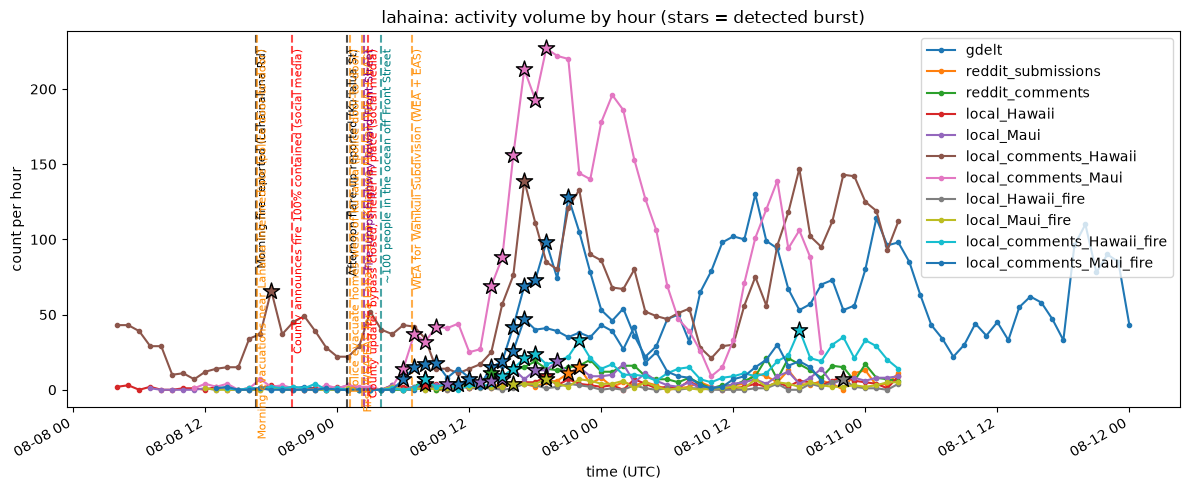

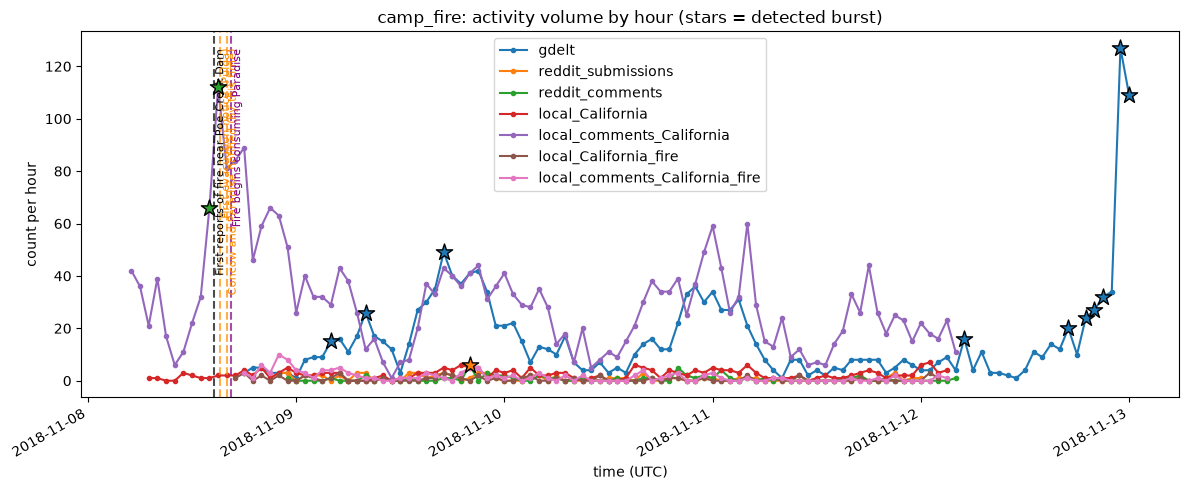

In [28]:
import matplotlib.pyplot as plt

def plot_case_timeline(case):
    fig, ax = plt.subplots(figsize=(12, 5))
    plotted_any = False
    for label, result in burst_results[case].items():
        if result.empty:
            continue
        plotted_any = True
        ax.plot(result.index, result["count"], marker="o", markersize=3, label=label)
        bursts = result[result["burst"]]
        if not bursts.empty:
            ax.scatter(bursts.index, bursts["count"], marker="*", s=150, zorder=5,
                       edgecolors="black")

    category_colors = dict(zip(CATEGORIES, ["black", "red", "darkorange", "purple",
                                            "dimgray", "teal"]))
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()]
    for _, e in events.iterrows():
        color = category_colors.get(e["category"], "teal")
        ax.axvline(e["time_utc"], linestyle="--", color=color, alpha=0.7)
        label = e["event"] + (f" ({e['channel']})" if pd.notna(e["channel"]) and e["channel"] else "")
        ax.text(e["time_utc"], ax.get_ylim()[1] * 0.95, label, rotation=90, color=color,
                fontsize=8, va="top")

    if not plotted_any:
        print(f"{case}: nothing to plot (no sources with valid timestamps)")
        plt.close(fig)
        return

    ax.set_title(f"{case}: activity volume by hour (stars = detected burst)")
    ax.set_xlabel("time (UTC)")
    ax.set_ylabel("count per hour")
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

for case in CASES:
    plot_case_timeline(case)

## Lag: public activity vs. the official timeline

For each official event, hours between it and each source's **first
detected burst**. Positive means the burst came *after* the event; negative
means public activity spiked *before* it (e.g. people were talking about
the fire before the first warning went out). This is the core comparison
for the response-gap question.

In [29]:
lag_rows = []
for case in CASES:
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()]
    for label, result in burst_results[case].items():
        if result.empty or not result["burst"].any():
            continue
        first_burst = result.index[result["burst"]].min()
        for _, e in events.iterrows():
            lag_rows.append({
                "case": case,
                "source": label,
                "first_burst_utc": first_burst,
                "event": e["event"],
                "hours_after_event": round((first_burst - e["time_utc"]).total_seconds() / 3600, 1),
            })

if lag_rows:
    lags = pd.DataFrame(lag_rows)
    for case, g in lags.groupby("case"):
        print(f"\n=== {case}: hours from official event to first burst (negative = burst first) ===")
        print(g.pivot(index="source", columns="event", values="hours_after_event").to_string())
else:
    print("Nothing to compare yet -- fill in OFFICIAL_TIMELINE times above.")


=== camp_fire: hours from official event to first burst (negative = burst first) ===
event                      Concow and Paradise notified (by this time)  Fire begins consuming Paradise  First evacuation notice (Pulga)  First reports of fire near Poe Creek Dam
source                                                                                                                                                                           
gdelt                                                             12.0                            11.5                             12.8                                      13.4
local_comments_California                                         -2.0                            -2.5                             -1.2                                      -0.6
reddit_comments                                                   28.0                            27.5                             28.8                                      29.4

=== lahaina: hours from

## Quick content check
Sample titles/text per source, so you can eyeball whether the keyword search actually pulled relevant content.

In [30]:
for case in CASES:
    print(f"\n=== {case} ===")
    for label, df in data[case].items():
        print(f"\n-- {label} ({len(df)} rows) --")
        if "title" in df.columns:
            print(df["title"].head(5).to_string(index=False))
        elif "body" in df.columns:
            print(df["body"].astype(str).str.slice(0, 120).head(5).to_string(index=False))
        if "domain" in df.columns:
            print("Top domains:")
            print(df["domain"].value_counts().head(10))
        if "subreddit" in df.columns:
            print("Subreddit breakdown:")
            print(df["subreddit"].value_counts().head(10))


=== lahaina ===

-- gdelt (3875 rows) --
Death toll from Maui wildfires rises to 67 as s...
Maui wildfires live updates : Death toll climbs...
Death toll from Maui wildfires rises to 67 as s...
Death toll in Maui disaster hits 67 , deadliest...
Maui wildfires live updates : Lahaina resembles...
Top domains:
domain
yahoo.com               71
kitv.com                58
cnn.com                 30
caledonianrecord.com    29
dailymail.co.uk         24
iheart.com              21
usatoday.com            20
staradvertiser.com      20
abc7news.com            19
independent.co.uk       19
Name: count, dtype: int64

-- reddit_submissions (212 rows) --
           Front Street in Lahaina on fire (video)
                              Lahaina town on fire
BREAKING: Extremely dangerous massive wildfire ...
Almost all sides of Maui, Hawaii is currently o...
Lahaina fire (and kudos to Walmart and American...
Top domains:
domain
i.redd.it              25
self.maui              16
v.redd.it              

## Readable timeline figure

A cleaner version of the timeline plot for reports and journals:
**local time**, one panel per kind of source (each with its own scale),
**fire-related** local posts only, and a few numbered key events instead of
every label. Hours with no posts are drawn as 0 from when each source's search
window began (`SEARCHED_FROM_UTC`) -- those hours were searched and nothing was found.

Choose which `OFFICIAL_TIMELINE` events get a numbered marker in `KEY_EVENTS`
(names must match exactly), and the time window in `PLOT_WINDOW`.

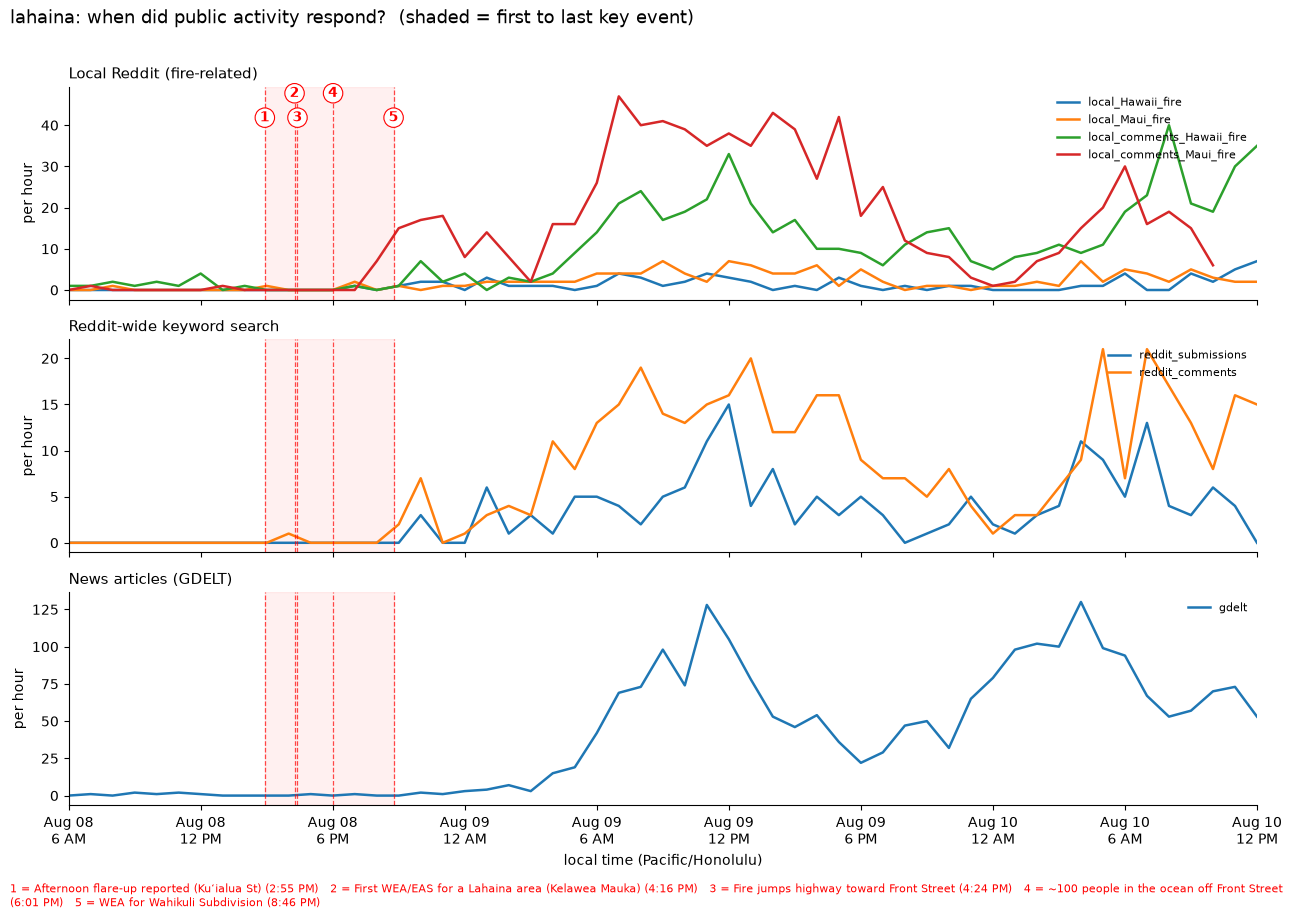

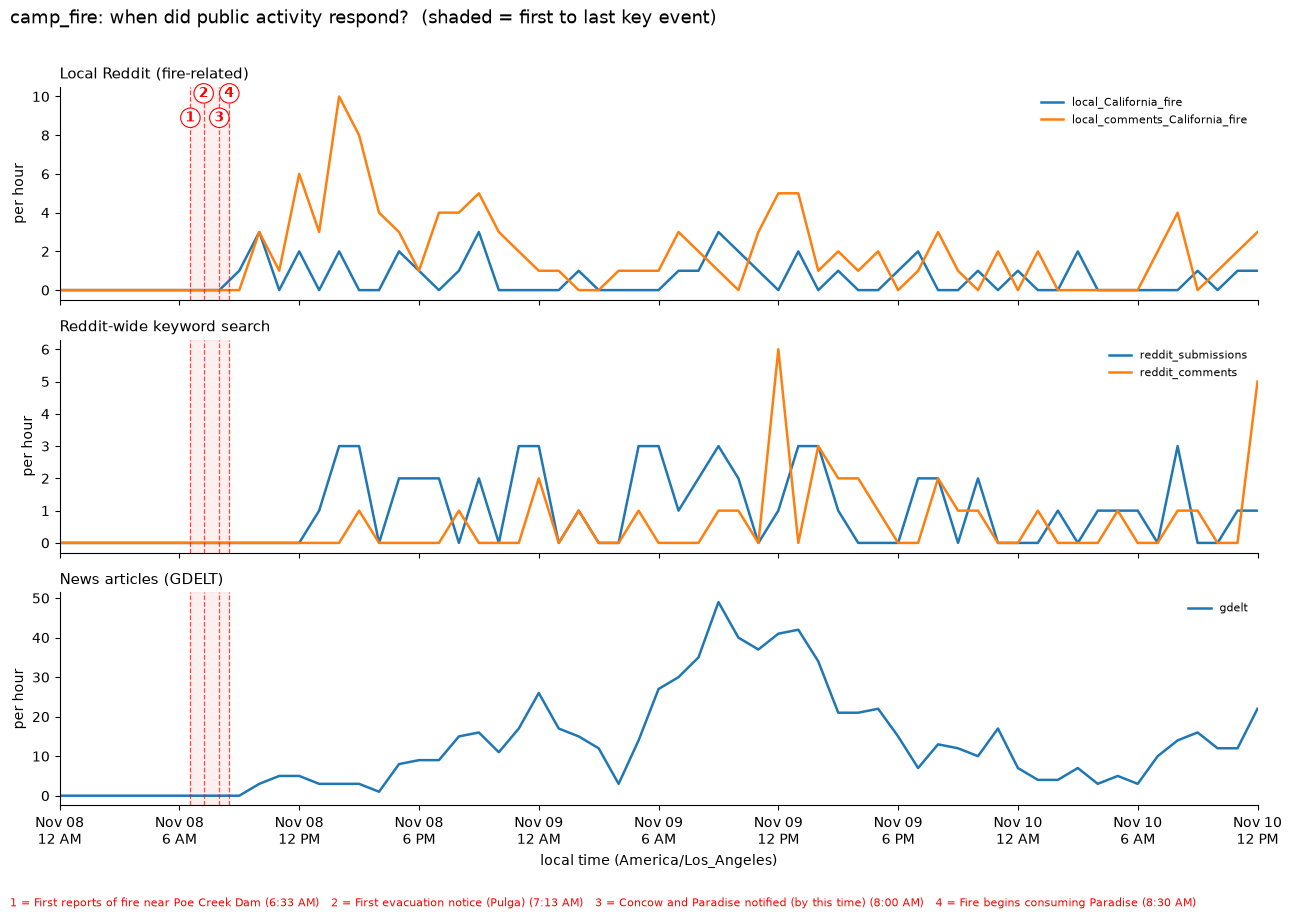

In [31]:
import matplotlib.dates as mdates

KEY_EVENTS = {
    "lahaina": ["Afternoon flare-up reported (Kuʻialua St)",
                "First WEA/EAS for a Lahaina area (Kelawea Mauka)",
                "Fire jumps highway toward Front Street",
                "~100 people in the ocean off Front Street",
                "WEA for Wahikuli Subdivision"],
    "camp_fire": ["First reports of fire near Poe Creek Dam",
                  "First evacuation notice (Pulga)",
                  "Concow and Paradise notified (by this time)",
                  "Fire begins consuming Paradise"],
}
PLOT_WINDOW = {  # local time
    "lahaina": ("2023-08-08 06:00", "2023-08-10 12:00"),
    "camp_fire": ("2018-11-08 00:00", "2018-11-10 12:00"),
}
# When each source's search window started (UTC), from collect_data.py / the logs.
# Hours between this and the first post are real zeros (searched, nothing found).
SEARCHED_FROM_UTC = {
    "lahaina": {"gdelt": "2023-08-08 00:00", "reddit": "2023-08-08 04:00"},
    "camp_fire": {"gdelt": "2018-11-08 00:00", "reddit": "2018-11-08 05:00"},
}
PANELS = [  # (title, which sources go in it)
    ("Local Reddit (fire-related)", lambda label: label.startswith("local") and label.endswith("_fire")),
    ("Reddit-wide keyword search", lambda label: label.startswith("reddit_")),
    ("News articles (GDELT)", lambda label: label == "gdelt"),
]


def hourly_local(case, label, x0, x1):
    """Hourly counts in local time, zero-filled within the span the file covers."""
    tz = CASE_TIMEZONES[case]
    df = data[case][label]
    ts = df["_timestamp"].dropna()
    raw = data[case].get(label[:-len("_fire")]) if label.endswith("_fire") else df
    span = (raw if raw is not None else df)["_timestamp"].dropna()
    if ts.empty or span.empty:
        return pd.Series(dtype=float)
    local = ts.dt.tz_localize("UTC").dt.tz_convert(tz).dt.floor("h")
    searched_from = pd.Timestamp(SEARCHED_FROM_UTC[case]["gdelt" if label == "gdelt" else "reddit"])
    lo = min(span.min(), searched_from).tz_localize("UTC").tz_convert(tz).floor("h")
    hi = span.max().tz_localize("UTC").tz_convert(tz).floor("h")
    hours = pd.date_range(max(lo, x0), min(hi, x1), freq="h")
    return local.value_counts().reindex(hours, fill_value=0)


def plot_readable(case):
    tz = CASE_TIMEZONES[case]
    x0, x1 = (pd.Timestamp(t, tz=tz) for t in PLOT_WINDOW[case])
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()]
    events = events[events["event"].isin(KEY_EVENTS.get(case, []))].sort_values("time_utc")
    event_times = [t.tz_localize("UTC").tz_convert(tz) for t in events["time_utc"]]
    missing = set(KEY_EVENTS.get(case, [])) - set(events["event"])
    if missing:
        print(f"{case}: KEY_EVENTS not found in OFFICIAL_TIMELINE (or no time yet): {sorted(missing)}")

    panels = [(title, [l for l in data[case] if pick(l) and not data[case][l].empty])
              for title, pick in PANELS]
    panels = [(title, labels) for title, labels in panels if labels]
    fig, axes = plt.subplots(len(panels), 1, figsize=(13, 2.8 * len(panels) + 0.8),
                             sharex=True, squeeze=False)
    axes = axes[:, 0]
    for ax, (title, labels) in zip(axes, panels):
        for label, color in zip(labels, plt.cm.tab10.colors):
            s = hourly_local(case, label, x0, x1)
            if not s.empty:
                ax.plot(s.index, s.values, color=color, lw=1.8, label=label)
        if len(event_times) >= 2:
            ax.axvspan(event_times[0], event_times[-1], color="red", alpha=0.06)
        for t in event_times:
            ax.axvline(t, color="red", ls="--", lw=0.9, alpha=0.7)
        ax.set_title(title, loc="left", fontsize=11)
        ax.set_ylabel("per hour")
        ax.legend(loc="upper right", fontsize=8, frameon=False)
        ax.spines[["top", "right"]].set_visible(False)

    ymax = axes[0].get_ylim()[1]
    for i, t in enumerate(event_times, 1):
        axes[0].text(t, ymax * (0.95 - 0.12 * (i % 2)), str(i), color="red", ha="center",
                     fontsize=10, fontweight="bold",
                     bbox=dict(fc="white", ec="red", boxstyle="circle,pad=0.2", lw=0.8))
    axes[-1].set_xlim(x0, x1)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%-I %p", tz=tz))
    axes[-1].set_xlabel(f"local time ({tz})")
    fig.suptitle(f"{case}: when did public activity respond?  (shaded = first to last key event)",
                 fontsize=13, x=0.01, ha="left")
    legend = "   ".join(f"{i} = {e} ({t.strftime('%-I:%M %p')})"
                        for i, (e, t) in enumerate(zip(events["event"], event_times), 1))
    fig.text(0.01, 0.005, legend, fontsize=8, color="red", wrap=True)
    plt.tight_layout(rect=(0, 0.03, 1, 0.97))
    plt.show()


for case in CASES:
    plot_readable(case)

## What kind of information was posted? (SetFit classifier)

Uses the SetFit classifier's output (`data/classifier/setfit_all.csv`, made by
`src/train_setfit.py --all`; see the README's *Classifier* section for how it
was trained and evaluated). Lahaina only so far.

- **Top:** fire-related posts per 3 hours in r/Maui + r/Hawaii (SetFit relevance).
- **Bottom:** share of those posts in each information category. Bins with fewer
  than `MIN_POSTS_PER_BIN` posts are greyed out: a share computed from a handful
  of posts is meaningless.

Caveat: on held-out posts, SetFit's category accuracy is 0.66, and it is weak on
*eyewitness* (F1 0.33) and can't be evaluated on *warning* (too few labeled
examples). Read the bottom panel as broad trends, not exact counts.

In [ ]:
CLASSIFIED = os.path.join(DATA_DIR, "classifier", "setfit_all.csv")
CATEGORY_WINDOW = ("2023-08-08 06:00", "2023-08-11 13:59")  # Hawaii time
BIN = "3h"
MIN_POSTS_PER_BIN = 20
CATEGORY_ORDER = ["eyewitness", "secondhand", "info_request", "warning",
                  "news_or_official", "help", "sympathy", "discussion"]
CATEGORY_COLORS = ["#c2185b", "#f06292", "#ef6c00", "#d50000",
                   "#1565c0", "#2e7d32", "#8e24aa", "#9e9e9e"]


def plot_categories(case="lahaina"):
    if not os.path.exists(CLASSIFIED):
        print(f"{CLASSIFIED} not found -- run: python src/train_setfit.py --all")
        return
    tz = CASE_TIMEZONES[case]
    c = pd.read_csv(CLASSIFIED, dtype={"id": str})
    posts = c[c["sf_relevant"]].copy()
    posts["t"] = pd.to_datetime(posts["time_hst"])
    posts = posts[posts["t"].between(*CATEGORY_WINDOW)]
    posts["bin"] = posts["t"].dt.floor(BIN)

    counts = (posts.pivot_table(index="bin", columns="sf_category", values="id", aggfunc="count", fill_value=0)
                   .reindex(columns=CATEGORY_ORDER, fill_value=0))
    counts = counts.reindex(pd.date_range(counts.index.min(), counts.index.max(), freq=BIN), fill_value=0)
    total = counts.sum(axis=1)
    share = counts.div(total.replace(0, 1), axis=0)
    share[total < MIN_POSTS_PER_BIN] = 0

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                                      gridspec_kw={"height_ratios": [1, 1.4]})
    width = pd.Timedelta(BIN) * 0.9
    top.bar(total.index, total.values, width=width, align="edge", color="#455a64")
    top.set_ylabel(f"fire posts per {BIN}")
    top.set_title("How many fire-related posts (SetFit, r/Maui + r/Hawaii)", loc="left", fontsize=11)

    bottom.stackplot(share.index, [share[k] for k in CATEGORY_ORDER], labels=CATEGORY_ORDER,
                     colors=CATEGORY_COLORS, alpha=0.9, step="post")
    for t in total.index[total < MIN_POSTS_PER_BIN]:
        bottom.axvspan(t, t + pd.Timedelta(BIN), color="#eeeeee", zorder=0)
    bottom.set_ylim(0, 1)
    bottom.set_ylabel("share of fire posts")
    bottom.set_title(f"What kind of information (grey = fewer than {MIN_POSTS_PER_BIN} posts)",
                     loc="left", fontsize=11)
    bottom.legend(loc="upper left", bbox_to_anchor=(1.0, 1), fontsize=9, frameon=False)

    # same key events as the readable timeline figure, converted to local (naive) time
    events = timeline[(timeline["case"] == case) & timeline["time_utc"].notna()
                      & timeline["event"].isin(KEY_EVENTS.get(case, []))].sort_values("time_utc")
    ymax = top.get_ylim()[1]
    key = []
    for i, (_, e) in enumerate(events.iterrows(), 1):
        t = e["time_utc"].tz_localize("UTC").tz_convert(tz).tz_localize(None)
        for ax in (top, bottom):
            ax.axvline(t, color="red", ls="--", lw=0.9)
        top.text(t, ymax * (0.95 - 0.12 * (i % 2)), str(i), color="red", ha="center", fontsize=9,
                 fontweight="bold", bbox=dict(fc="white", ec="red", boxstyle="circle,pad=0.2", lw=0.8))
        key.append(f"{i} = {e['event']} ({t:%-I:%M %p})")
    fig.text(0.01, 0.005, "   ".join(key), fontsize=8, color="red", wrap=True)
    for ax in (top, bottom):
        ax.spines[["top", "right"]].set_visible(False)
    bottom.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%-I %p"))
    bottom.set_xlabel(f"local time ({tz}), {BIN} bins")
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

    print("Fire-related posts by category over the whole window:")
    print(counts.sum().to_string())


plot_categories("lahaina")